# TALLER FINAL DE MINERÍA DE DATOS
## Segmentación de clientes con K-Means

**Profesor:** ORDONEZ QUINTERO, CRISTIAN CAMILO  
**Estudiante:** Dania Kathalina Urbina Portilla  
**Dataset:** Mall Customers Dataset

---

## Objetivo general
Desarrollar un modelo de segmentación de clientes con K-Means, utilizando el método del codo y el coeficiente de silueta para elegir el número de grupos, evaluar el modelo e interpretar los resultados desde la perspectiva del negocio.

## Objetivos específicos
- Comprender el funcionamiento de K-Means.
- Explorar y preprocesar el conjunto de datos.
- Determinar el número de clusters mediante métricas.
- Interpretar los segmentos y proponer estrategias de marketing.
- Preparar el despliegue de una aplicación interactiva con Streamlit.

**Nota metodológica:** la segmentación principal utiliza el ingreso anual y la puntuación de gasto. `CustomerID` es un identificador y no debe influir en las distancias; `Gender` es categórica y no se incluye en el modelo; `Age` se conserva para describir los segmentos después de entrenarlos.

# Parte 1. Exploración de datos

## 1.1 Cargar el dataset
Se utiliza el archivo `Mall_Customers.csv` entregado con el taller.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option("display.max_columns", None)
ruta = Path("Mall_Customers.csv")
if not ruta.exists():
    raise FileNotFoundError("Coloca Mall_Customers.csv en la misma carpeta que este cuaderno.")

df = pd.read_csv(ruta)
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
display(df.head())

Filas: 200 | Columnas: 5


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 1.2 Estructura y análisis descriptivo

In [2]:
print("Información general:")
df.info()
print("\nEstadísticas descriptivas:")
display(df.describe(include="all").T)
print("\nValores faltantes por variable:")
display(df.isna().sum().to_frame("Valores faltantes"))
print("\nRegistros duplicados:", int(df.duplicated().sum()))
print("\nDistribución por género:")
display(df["Gender"].value_counts().to_frame("Cantidad"))

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Estadísticas descriptivas:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,200.0,NaN,NaN,NaN,100.5,57.879185,1.0,50.75,100.5,150.25,200.0
Gender,200,2,Female,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,200.0,NaN,NaN,NaN,38.85,13.969007,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,NaN,NaN,NaN,60.56,26.264721,15.0,41.5,61.5,78.0,137.0
Spending Score (1-100),200.0,NaN,NaN,NaN,50.2,25.823522,1.0,34.75,50.0,73.0,99.0



Valores faltantes por variable:


,Valores faltantes
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0



Registros duplicados: 0

Distribución por género:


,Cantidad
Gender,
Female,112
Male,88


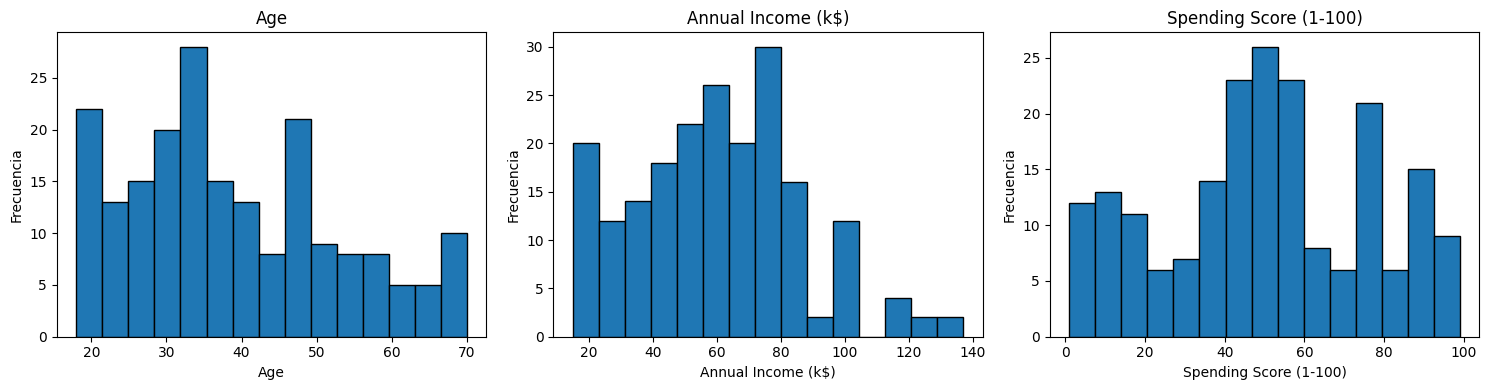

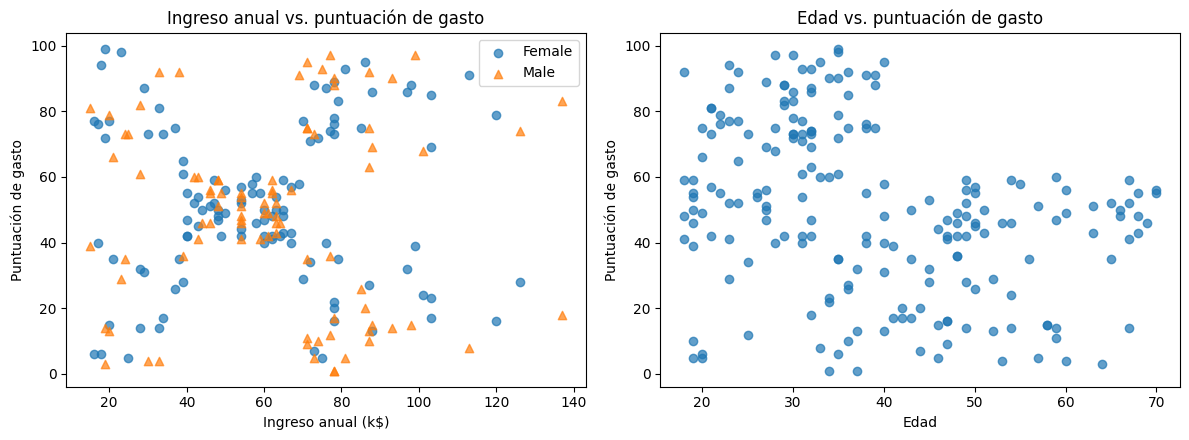

Correlaciones entre variables numéricas:


,Age,Annual Income (k$),Spending Score (1-100)
Age,1.000,-0.012,-0.327
Annual Income (k$),-0.012,1.000,0.010
Spending Score (1-100),-0.327,0.010,1.000


In [3]:
variables_numericas = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, variable in zip(axes, variables_numericas):
    ax.hist(df[variable], bins=15, edgecolor="black")
    ax.set_title(variable)
    ax.set_xlabel(variable)
    ax.set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for genero, grupo in df.groupby("Gender"):
    marcador = "o" if genero == "Female" else "^"
    axes[0].scatter(grupo["Annual Income (k$)"], grupo["Spending Score (1-100)"],
                    marker=marcador, alpha=0.7, label=genero)
axes[0].set_xlabel("Ingreso anual (k$)")
axes[0].set_ylabel("Puntuación de gasto")
axes[0].set_title("Ingreso anual vs. puntuación de gasto")
axes[0].legend()

axes[1].scatter(df["Age"], df["Spending Score (1-100)"], alpha=0.7)
axes[1].set_xlabel("Edad")
axes[1].set_ylabel("Puntuación de gasto")
axes[1].set_title("Edad vs. puntuación de gasto")
plt.tight_layout()
plt.show()

print("Correlaciones entre variables numéricas:")
display(df[variables_numericas].corr().round(3))

### Respuestas de la Parte 1

**¿Qué variables son más adecuadas para segmentar clientes?**  
Las variables principales son `Annual Income (k$)` y `Spending Score (1-100)`. El ingreso permite distinguir la capacidad económica y la puntuación de gasto representa el comportamiento de compra. Juntas forman segmentos fáciles de interpretar para marketing. `CustomerID` solo identifica al cliente y no aporta una característica de comportamiento. La edad y el género pueden servir para describir los grupos, pero no se incorporan al modelo principal.

**¿Se identifican valores atípicos?**  
Con el criterio del rango intercuartílico (IQR), se identifican dos observaciones con ingreso anual de 137 k$, por encima del límite superior calculado. No se eliminan automáticamente: son ingresos altos, pero no hay evidencia en el archivo de que sean errores. No se detectan valores atípicos por este criterio en edad ni en puntuación de gasto.

**¿Qué tipo de relaciones se observan entre las variables?**  
La correlación lineal entre ingreso anual y puntuación de gasto es prácticamente nula (aproximadamente 0,01). Esto no significa que no existan patrones: en el diagrama aparecen grupos con combinaciones diferentes de ingreso y gasto. La relación entre edad y puntuación de gasto es negativa moderada (aproximadamente -0,33), lo que sugiere que las puntuaciones tienden a ser menores en clientes de mayor edad, aunque no determina el comportamiento de cada persona.

# Parte 2. Preprocesamiento

K-Means utiliza distancias euclidianas. Por eso, las variables numéricas se escalan con `StandardScaler` antes de entrenar el modelo.

In [4]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

resumen_escalado = pd.DataFrame({
    "Variable": features,
    "Media después de escalar": X_scaled.mean(axis=0),
    "Desviación estándar después de escalar": X_scaled.std(axis=0)
})
display(resumen_escalado.round(4))

,Variable,Media después de escalar,Desviación estándar después de escalar
0,Annual Income (k$),-0.0,1.0
1,Spending Score (1-100),-0.0,1.0


### Respuesta de la Parte 2

**¿Por qué es necesario escalar las variables en K-Means?**  
K-Means calcula distancias y las variables con escalas o dispersiones mayores pueden dominar el resultado. `StandardScaler` transforma cada variable para que tenga media cercana a 0 y desviación estándar cercana a 1. Así, el ingreso y la puntuación de gasto contribuyen de forma comparable a la distancia. El escalado se ajusta con los datos disponibles y debe reutilizarse para transformar clientes nuevos.

# Parte 3. Método del codo

Se calcula la inercia para valores de K entre 1 y 10. La inercia corresponde a la suma de las distancias cuadráticas de los puntos a sus centroides.

,K,Inercia
0,1,400.000
1,2,269.691
2,3,157.704
3,4,108.921
4,5,65.568
5,6,55.057
6,7,44.865
7,8,37.228
8,9,32.392
9,10,29.982


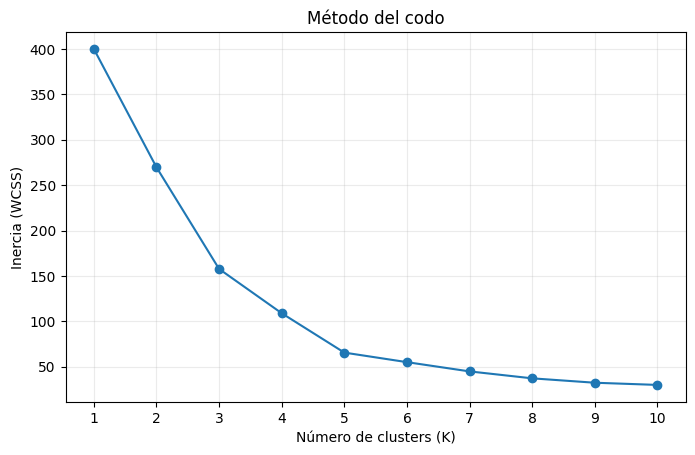

In [5]:
ks_elbow = list(range(1, 11))
inertias = []
for k in ks_elbow:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    modelo.fit(X_scaled)
    inertias.append(modelo.inertia_)

tabla_codo = pd.DataFrame({"K": ks_elbow, "Inercia": inertias})
display(tabla_codo.round(3))

plt.figure(figsize=(8, 4.8))
plt.plot(ks_elbow, inertias, marker="o")
plt.xticks(ks_elbow)
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inercia (WCSS)")
plt.title("Método del codo")
plt.grid(True, alpha=0.25)
plt.show()

### Respuestas de la Parte 3

**¿Por qué valores cercanos a cero indican mejor ajuste?**  
Una inercia baja indica que los puntos quedan cerca de los centroides de sus grupos. Una inercia igual a cero significaría que cada punto coincide con el centroide de su grupo. Sin embargo, la inercia disminuye al aumentar K, por lo que no se debe elegir automáticamente el K más grande.

**¿Cómo se identifica el punto óptimo de K?**  
Se busca el punto donde la reducción de la inercia deja de ser tan pronunciada y la curva comienza a aplanarse. En este dataset, K=5 es una elección razonable: después de ese punto, la mejora de la inercia es bastante menor que la observada al pasar de K=4 a K=5. Esta elección se contrasta con el coeficiente de silueta.

# Parte 4. Coeficiente de silueta

El coeficiente de silueta compara qué tan cerca está cada observación de su propio cluster frente al cluster alternativo más cercano. Se calcula para K entre 2 y 10.

,K,Coeficiente de silueta
0,2,0.3213
1,3,0.4666
2,4,0.4939
3,5,0.5547
4,6,0.5399
5,7,0.5281
6,8,0.4552
7,9,0.4571
8,10,0.4432


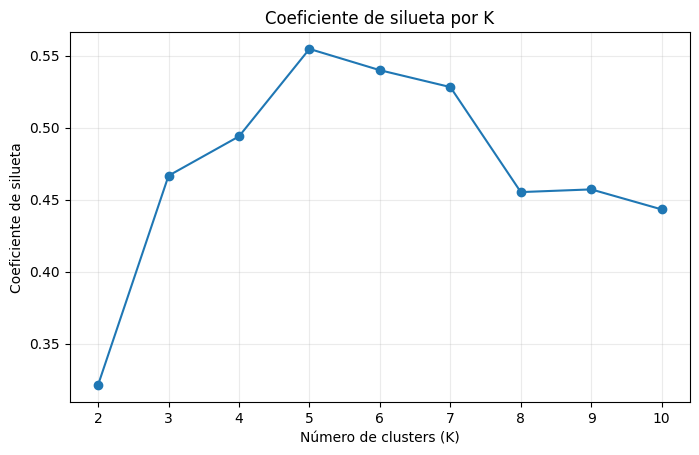

Mayor silueta: K=5, coeficiente=0.5547


In [6]:
ks_silhouette = list(range(2, 11))
silhouette_values = []
for k in ks_silhouette:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(X_scaled)
    silhouette_values.append(silhouette_score(X_scaled, etiquetas))

tabla_silueta = pd.DataFrame({
    "K": ks_silhouette,
    "Coeficiente de silueta": silhouette_values
})
display(tabla_silueta.round(4))

plt.figure(figsize=(8, 4.8))
plt.plot(ks_silhouette, silhouette_values, marker="o")
plt.xticks(ks_silhouette)
plt.xlabel("Número de clusters (K)")
plt.ylabel("Coeficiente de silueta")
plt.title("Coeficiente de silueta por K")
plt.grid(True, alpha=0.25)
plt.show()

k_silueta = ks_silhouette[int(np.argmax(silhouette_values))]
print(f"Mayor silueta: K={k_silueta}, coeficiente={max(silhouette_values):.4f}")

### Respuestas de la Parte 4

**¿Qué mide el coeficiente de silueta?**  
Mide la cohesión y separación de los clusters: compara la distancia de una observación a su propio grupo con la distancia al grupo alternativo más cercano.

**¿Qué significa un valor cercano a 1?**  
Que la observación está bien asignada: queda cerca de los miembros de su cluster y lejos de otros grupos.

**¿Qué implica un valor cercano a 0 o negativo?**  
Un valor cercano a 0 indica que la observación está en una frontera entre grupos. Un valor negativo puede indicar que estaría más cerca de otro cluster que del que se le asignó.

**¿Coincide el valor óptimo de K con el método del codo? Justifique.**  
Sí. El coeficiente de silueta más alto se obtiene con K=5 (aproximadamente 0,555), y ese valor también coincide con el punto de inflexión razonable de la curva del codo. Por ello, se seleccionan cinco clusters. La métrica apoya la decisión, aunque la interpretación de negocio también debe considerarse.

# Parte 5. Modelo K-Means

Se entrena el modelo final con K=5, una semilla fija (`random_state=42`) y diez inicializaciones (`n_init=10`) para facilitar la reproducibilidad.

Centroides expresados en las unidades originales:


,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


,Clientes,Edad_promedio,Ingreso_promedio,Gasto_promedio,Porcentaje_mujeres
Cluster,,,,,
0,81,42.72,55.30,49.52,59.26
1,39,32.69,86.54,82.13,53.85
2,22,25.27,25.73,79.36,59.09
3,35,41.11,88.20,17.11,45.71
4,23,45.22,26.30,20.91,60.87


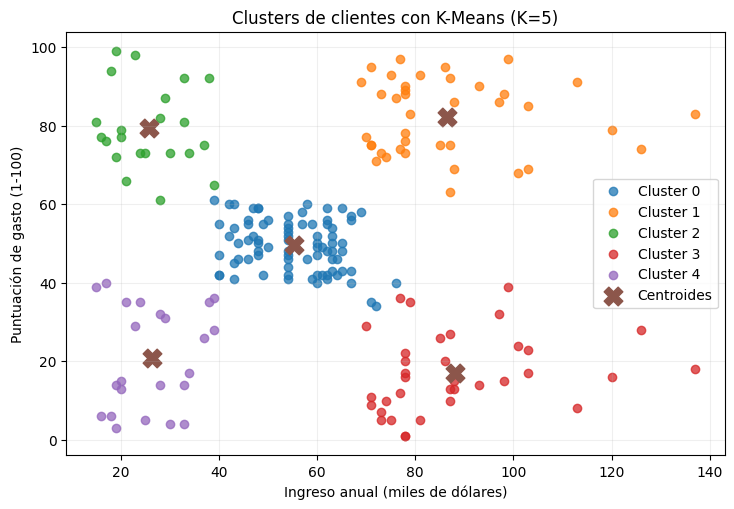

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
5,6,Female,22,17,76,2
6,7,Female,35,18,6,4
7,8,Female,23,18,94,2
8,9,Male,64,19,3,4
9,10,Female,30,19,72,2


In [7]:
K_FINAL = 5
modelo_final = KMeans(n_clusters=K_FINAL, random_state=42, n_init=10)
df_resultado = df.copy()
df_resultado["Cluster"] = modelo_final.fit_predict(X_scaled)

centroides_originales = pd.DataFrame(
    scaler.inverse_transform(modelo_final.cluster_centers_),
    columns=features
)
centroides_originales.index.name = "Cluster"

print("Centroides expresados en las unidades originales:")
display(centroides_originales.round(2))

resumen_clusters = df_resultado.groupby("Cluster").agg(
    Clientes=("CustomerID", "count"),
    Edad_promedio=("Age", "mean"),
    Ingreso_promedio=("Annual Income (k$)", "mean"),
    Gasto_promedio=("Spending Score (1-100)", "mean"),
    Porcentaje_mujeres=("Gender", lambda s: 100 * (s == "Female").mean())
).round(2)
display(resumen_clusters)

plt.figure(figsize=(8.5, 5.5))
for cluster_id in sorted(df_resultado["Cluster"].unique()):
    grupo = df_resultado[df_resultado["Cluster"] == cluster_id]
    plt.scatter(grupo[features[0]], grupo[features[1]], alpha=0.75, label=f"Cluster {cluster_id}")
plt.scatter(centroides_originales[features[0]], centroides_originales[features[1]],
            marker="X", s=180, label="Centroides")
plt.xlabel("Ingreso anual (miles de dólares)")
plt.ylabel("Puntuación de gasto (1-100)")
plt.title("Clusters de clientes con K-Means (K=5)")
plt.legend()
plt.grid(True, alpha=0.2)
plt.show()

display(df_resultado.head(10))

### Respuestas de la Parte 5

**¿Qué representa cada cluster?**  
Cada cluster agrupa clientes con valores similares de ingreso anual y puntuación de gasto. Los números de cluster son etiquetas técnicas, no una clasificación de mejor a peor. Para este ajuste, los perfiles medios son:

- **Cluster 0:** ingreso y gasto intermedios; representa clientes promedio.
- **Cluster 1:** ingreso alto y puntuación de gasto alta; representa clientes de alto valor.
- **Cluster 2:** ingreso bajo y puntuación de gasto alta; clientes que gastan bastante en relación con su ingreso, posiblemente sensibles al presupuesto.
- **Cluster 3:** ingreso alto y puntuación de gasto baja; representa una oportunidad de crecimiento.
- **Cluster 4:** ingreso bajo y puntuación de gasto baja; representa bajo valor actual.

**¿Qué diferencias existen entre los grupos obtenidos?**  
Los grupos se distinguen por las combinaciones de ingreso y gasto, no solo por una variable. Hay clientes de ingreso alto que gastan poco y clientes de ingreso más bajo con puntuaciones de gasto elevadas. Por eso no sería correcto tratar a todos los clientes de ingreso alto como los más activos ni asumir que todos los de ingreso bajo gastan poco.

# Parte 6. Interpretación de negocio

Los perfiles son orientativos: el dataset no incluye compras reales, margen, frecuencia, antigüedad ni rentabilidad. La puntuación de gasto funciona como una aproximación del comportamiento, no como una medición completa del valor de vida del cliente.

In [8]:
estrategias = pd.DataFrame([
    {
        "Cluster / perfil": "1 - Clientes de alto valor",
        "Características": "Ingreso alto y puntuación de gasto alta.",
        "Estrategia sugerida": "Programa VIP, beneficios exclusivos, preventas, atención personalizada y recompensas por fidelidad."
    },
    {
        "Cluster / perfil": "0 - Clientes promedio",
        "Características": "Ingreso y gasto intermedios.",
        "Estrategia sugerida": "Venta cruzada, recomendaciones de productos complementarios, promociones moderadas y campañas de retención."
    },
    {
        "Cluster / perfil": "4 - Bajo valor actual",
        "Características": "Ingreso bajo y puntuación de gasto baja.",
        "Estrategia sugerida": "Ofertas de entrada, paquetes económicos y comunicación de valor; evitar descuentos costosos sin medir resultados."
    },
    {
        "Cluster / perfil": "3 - Clientes con potencial",
        "Características": "Ingreso alto y puntuación de gasto baja.",
        "Estrategia sugerida": "Encuestas de preferencias, recomendaciones personalizadas, pruebas de producto y ofertas selectivas para entender barreras de compra."
    },
    {
        "Cluster / perfil": "2 - Alto gasto con ingreso limitado",
        "Características": "Ingreso bajo y puntuación de gasto alta.",
        "Estrategia sugerida": "Beneficios de fidelidad accesibles, paquetes de precio claro y recompensas pequeñas por recurrencia."
    },
])
display(estrategias)

,Cluster / perfil,Características,Estrategia sugerida
0,1 - Clientes de alto valor,Ingreso alto y puntuación de gasto alta.,"Programa VIP, beneficios exclusivos, preventas..."
1,0 - Clientes promedio,Ingreso y gasto intermedios.,"Venta cruzada, recomendaciones de productos co..."
2,4 - Bajo valor actual,Ingreso bajo y puntuación de gasto baja.,"Ofertas de entrada, paquetes económicos y comu..."
3,3 - Clientes con potencial,Ingreso alto y puntuación de gasto baja.,"Encuestas de preferencias, recomendaciones per..."
4,2 - Alto gasto con ingreso limitado,Ingreso bajo y puntuación de gasto alta.,"Beneficios de fidelidad accesibles, paquetes d..."


### Respuestas de la Parte 6

**¿Qué estrategias de marketing se podrían aplicar a cada grupo?**  
A los clientes de alto valor se les pueden ofrecer beneficios VIP y atención personalizada. A los clientes promedio, venta cruzada y campañas de retención. A los de bajo valor actual, opciones económicas y promociones controladas. A los clientes con potencial (ingreso alto y gasto bajo), recomendaciones personalizadas e investigación de las barreras que frenan su gasto. A los clientes de alto gasto con ingreso limitado, recompensas accesibles y paquetes económicos.

**¿Qué segmento representa mayor oportunidad de crecimiento?**  
El cluster 3, con ingreso promedio aproximado de 88,2 k$ y puntuación de gasto promedio de 17,1, es una oportunidad importante: cuenta con capacidad económica relativa, pero su puntuación de gasto es baja. Una campaña personalizada podría aumentar su participación. La oportunidad debe validarse con pruebas A/B y datos de ventas reales; una puntuación baja no demuestra por sí sola que el cliente esté dispuesto a comprar más.

# Parte 7. Despliegue con Streamlit

Se entrega el archivo `app.py` junto con este cuaderno y el dataset. La aplicación permite visualizar la curva del codo, consultar el coeficiente de silueta, explorar los clusters e introducir un cliente nuevo para asignarlo automáticamente a un grupo.

## Cómo ejecutar la aplicación

1. Instalar Python 3.10 o superior.
2. Abrir una terminal en la carpeta del proyecto.
3. Instalar las dependencias con `pip install -r requirements.txt`.
4. Ejecutar `streamlit run app.py`.
5. Abrir la dirección local que Streamlit muestra en la terminal.

El modelo usa las mismas variables y el mismo `StandardScaler` para transformar los clientes nuevos. No se debe escalar el nuevo cliente con estadísticas diferentes a las del modelo entrenado.

# Conclusiones

1. El dataset contiene 200 observaciones y cinco columnas; no presenta valores faltantes ni registros duplicados.
2. Para la segmentación se seleccionaron ingreso anual y puntuación de gasto, mientras que la edad se utilizó para describir los grupos.
3. `StandardScaler` permite que las variables contribuyan de forma comparable a las distancias utilizadas por K-Means.
4. Tanto el método del codo como la silueta respaldan K=5; el coeficiente de silueta máximo observado es aproximadamente 0,555.
5. Los cinco grupos sugieren estrategias de marketing distintas, especialmente para clientes de alto valor y clientes con ingreso alto pero puntuación de gasto baja.
6. La aplicación Streamlit permite explorar el resultado y clasificar observaciones nuevas. Los perfiles deben validarse con datos comerciales adicionales antes de tomar decisiones reales.

## Limitaciones
El dataset es pequeño y no contiene historial transaccional, rentabilidad, frecuencia de compra ni respuesta a campañas. Los clusters describen patrones de este conjunto de datos y no prueban causalidad ni garantizan el comportamiento futuro de los clientes.